# Bài toán minh họa 1

# Import thư viện

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Bài toán minh họa

Một robot cần chăm sóc một tập hợp các cây có tọa độ cố định trên mặt phẳng 2D. Với mỗi cây, robot đi thẳng từ vị trí đặt trạm đến cây rồi quay về chính trạm đó trước khi đi đến cây tiếp theo. Hãy chọn vị trí đặt trạm $(x,y)$ sao cho tổng quãng đường đi và về là nhỏ nhất.

Trong bài này, “quay về điểm xuất phát” nghĩa là quay về trạm $(x,y)$ đang được lựa chọn, không phải một gốc tọa độ cố định. Biến `robot` trong code biểu diễn vị trí trạm đang được thử; các bước Gradient Descent cập nhật vị trí này, không mô phỏng hành trình chăm sóc cây.

Gọi $(a_i,b_i)$ là tọa độ cây thứ $i$. Tổng quãng đường thực tế, bao gồm cả lượt đi và lượt về, là:
$$
D_{\mathrm{round\ trip}}(x,y)=2\sum_{i=0}^{n-1}\sqrt{(x-a_i)^2+(y-b_i)^2}.
$$

Để đơn giản hóa bài toán tối ưu, ta định nghĩa tổng khoảng cách một chiều:
$$
L(x,y)=\sum_{i=0}^{n-1}\sqrt{(x-a_i)^2+(y-b_i)^2}.
$$

Vì nhân với hằng số dương $2$ không thay đổi thứ tự so sánh giữa các vị trí trạm, ta có:
$$
\operatorname*{arg\,min}_{x,y}D_{\mathrm{round\ trip}}(x,y)
=\operatorname*{arg\,min}_{x,y}L(x,y).
$$

Do đó, code bên dưới tối ưu $L(x,y)$. Khi báo cáo quãng đường thực tế robot phải đi, ta nhân giá trị này với $2$.

**Lưu ý:** Hai hàm mục tiêu có cùng vị trí tối ưu, nhưng gradient của $D_{\mathrm{round\ trip}}$ bằng $2$ lần gradient của $L$. Với cùng learning rate và ngưỡng dừng, quá trình cập nhật và vị trí xấp xỉ tại thời điểm dừng có thể khác nhau.


# Dữ liệu mẫu

In [2]:
trees = [(1, 5), (2, 3), (3, 4), (2, 4), (3, 5)]
robot = (1, 1)

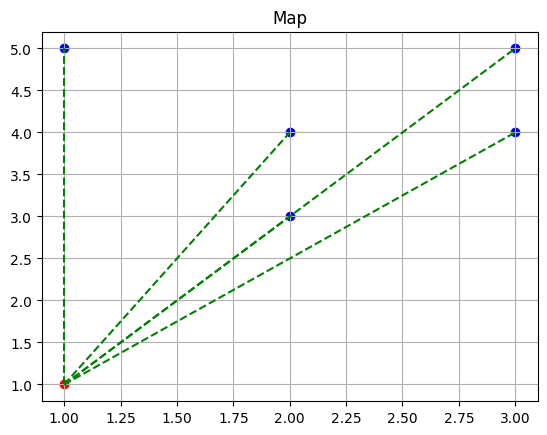

In [3]:
plt.title('Map')    
plt.grid()
plt.scatter(list(x[0] for x in trees), list(x[1] for x in trees), marker='o', color='blue') 
plt.scatter(robot[0], robot[1], color='red')

for tree in trees:
  plt.plot([robot[0], tree[0]], [robot[1], tree[1]], 'green', linestyle='--')

plt.show()

In [4]:
import plotly.graph_objects as go

def f(x, y):
    distance = [(((x - t[0])**2 + (y - t[1])**2))**0.5 for t in trees]
    return sum(distance)

x = np.linspace(-5, 5, 100)
y = np.linspace(-5, 5, 100)
X, Y = np.meshgrid(x, y)
Z = f(X, Y)
fig = go.Figure(data=[go.Surface(x=X, y=Y, z=Z)])
fig.update_layout(
    title='One-way distance objective L(x, y)',
    scene=dict(xaxis_title='Base x', yaxis_title='Base y', zaxis_title='L(x, y)'),
    autosize=False, width=800, height=600
)
fig.show()

# Gradient Descent

Với vị trí trạm không trùng với bất kỳ cây nào, đặt $d_i=\sqrt{(x-a_i)^2+(y-b_i)^2}$, gradient của hàm mục tiêu một chiều là:
$$
\nabla L(x,y)=\sum_{i=0}^{n-1}\frac{(x-a_i,\;y-b_i)}{d_i}.
$$

`evaluate_total_distance()` trả về $L$ và `compute_gradient()` tính $\nabla L$. Giá trị `one_way_objective` trong log là hàm mục tiêu đang được tối ưu, chưa phải tổng quãng đường đi và về.


In [5]:
class GradientDescent:
    def __init__(self, robot, trees):
        self.robot = np.array(robot, dtype=np.float64)
        self.trees = np.array(trees, dtype=np.float64)
    
    def evaluate_total_distance(self):
        """Tính L: tổng khoảng cách một chiều từ trạm đến tất cả các cây."""
        distances = np.sqrt(np.sum((self.robot - self.trees) ** 2, axis=1))
        return np.sum(distances)

    def compute_gradient(self):
        """Tính gradient của L theo hai tọa độ trạm x và y."""
        diff = self.robot - self.trees
        distances = np.sqrt(np.sum(diff ** 2, axis=1))
        gradient = np.sum(diff / distances[:, np.newaxis], axis=0)
        return gradient
    
    def is_gradient_small(self, gradient, threshold=1e-9):
        """Kiểm tra xem giá trị gradient có nhỏ hơn một ngưỡng cho trước không."""
        return np.all(np.abs(gradient) < threshold)

    def gradient_descent(self, learning_rate, threshold=1e-9):
        """Thực hiện thuật toán gradient descent."""
        step = 0
        while True:
            gradient = self.compute_gradient()
            if self.is_gradient_small(gradient, threshold):
                break
            print(f"learning rate: {learning_rate}")
            print(f"gradient: {gradient}")
            print(f"combine: {learning_rate * gradient}")
            self.robot -= learning_rate * gradient
            step += 1
            print(f'> Step {step}: robot = {self.robot.tolist()} | one_way_objective = {self.evaluate_total_distance()} | gradient = {gradient.tolist()}')
        return self.robot, self.evaluate_total_distance()


# Run

In [6]:
print(f"Start position is {robot}")
trees = [(1, 5), (2, 3), (3, 4), (2, 4), (3, 5)]
robot = (1, 1)
gradient_descent = GradientDescent(robot, trees)
results = gradient_descent.gradient_descent(learning_rate=0.05, threshold=1e-3)

Start position is (1, 1)
learning rate: 0.05
gradient: [-1.76535515 -4.56958797]
combine: [-0.08826776 -0.2284794 ]
> Step 1: robot = [1.0882677576620992, 1.2284793987194096] | one_way_objective = 16.27782864573682 | gradient = [-1.7653551532419829, -4.569587974388189]
learning rate: 0.05
gradient: [-1.76662661 -4.55392182]
combine: [-0.08833133 -0.22769609]
> Step 2: robot = [1.1765990882339947, 1.4561754894759922] | one_way_objective = 15.086908782046791 | gradient = [-1.7666266114379114, -4.553921815131649]
learning rate: 0.05
gradient: [-1.76889187 -4.53447526]
combine: [-0.08844459 -0.22672376]
> Step 3: robot = [1.2650436814889934, 1.6828992526695556] | one_way_objective = 13.90490265878906 | gradient = [-1.7688918650999716, -4.534475263871269]
learning rate: 0.05
gradient: [-1.77280831 -4.50985711]
combine: [-0.08864042 -0.22549286]
> Step 4: robot = [1.3536840967610086, 1.9083921079688595] | one_way_objective = 12.733983460698408 | gradient = [-1.7728083054403039, -4.5098571059

Best base position: [2.04572327 4.01893437]
One-way objective L: 4.826423014900124
Actual round-trip distance (2L): 9.652846029800248


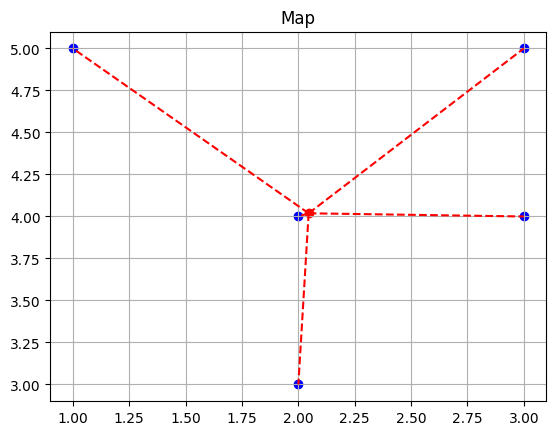

In [7]:
best_position = results[0]
best_one_way_distance = results[1]
best_round_trip_distance = 2 * best_one_way_distance
print(f"Best base position: {best_position}")
print(f"One-way objective L: {best_one_way_distance}")
print(f"Actual round-trip distance (2L): {best_round_trip_distance}")

plt.title('Map')    
plt.grid()
plt.scatter(list(x[0] for x in trees), list(x[1] for x in trees), marker='o', color = 'blue')
plt.scatter(best_position[0], best_position[1], color = 'red')
for tree in trees:
  plt.plot([best_position[0], tree[0]], [best_position[1], tree[1]], 'red', linestyle = '--')
plt.show()


# Bài toán minh họa 2

# Import thư viện

In [8]:
import numpy as np
from matplotlib import pyplot as plt
import random


# Dữ liệu bài toán
Xét bài toán yêu cầu xây dựng một mô hình hồi quy tuyến tính để dự đoán mức lương của một cá nhân dựa trên số năm kinh nghiệm làm việc của họ. Dữ liệu được cung cấp bao gồm các cặp giá trị của số năm kinh nghiệm và mức lương tương ứng. Bằng cách áp dụng hồi quy tuyến tính, chúng ta sẽ tìm ra đường thẳng tối ưu để mô hình hóa mối quan hệ này, từ đó có thể sử dụng mô hình để dự đoán mức lương cho những người có số năm kinh nghiệm khác nhau.

Mô tả về dữ liệu đầu vào như sau:
- `X_train`: Mảng numpy chứa các giá trị số năm kinh nghiệm (Experience) của một số cá nhân.
- `y_train`: Mảng numpy chứa các giá trị mức lương (Salary) tương ứng với số năm kinh nghiệm.

In [9]:
X_train = np.array([1, 2, 2.5, 3.5, 3, 4, 5, 1.5, 4, 4.5])
y_train = np.array([10, 25, 20, 30, 28, 50, 70, 18, 40, 50])
num_data = X_train.shape[0]

Visualize tập dữ liệu

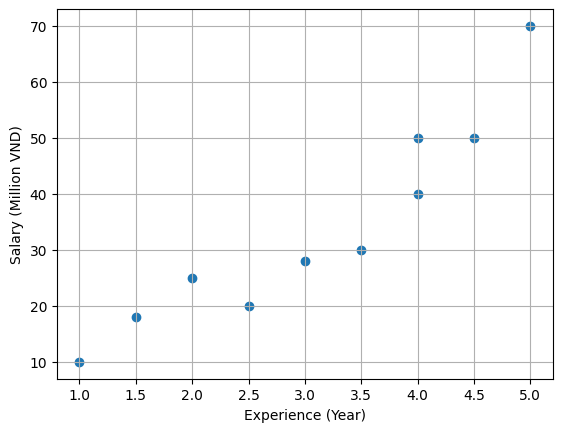

In [10]:
plt.scatter(X_train, y_train)
plt.xlabel('Experience (Year)')
plt.ylabel('Salary (Million VND)')
plt.grid()
plt.show()

Thêm một chiều cho các điểm dữ liệu trong `X_train`. Chiều mới này của các điểm dữ liệu sẽ có giá trị là 1.

In [11]:
X_train = np.stack((np.ones(num_data), X_train), axis=1)
num_dims = X_train.shape[1]

# Ký hiệu toán học sử dụng

- $N$ số lượng điểm trong tập dữ liệu.
- $x_i$ thuộc tính của điểm dữ liệu thứ $i$.
- $y_i$ nhãn của điểm dữ liệu thứ $i$.
- $w$ tham số của mô hình.

Hàm mất mát

$$\mathcal{L}(w) = \frac{1}{2}\sum_{i=1}^N (w^Tx_i-y_i)^2$$

Gradient của hàm mất mát

$$\nabla_{w}\mathcal{L}(w) = \sum_{i=1}^N x_i(w^Tx_i - y_i)$$

# Hàm hỗ trợ

Hàm tính giá trị gradient cho hàm mất mát $\mathcal{L}(w)$



In [12]:
def calculate_grad(w, X, y):
    error = X @ w - y
    grad = X.T @ error
    return grad

Hàm chia bộ dữ liệu thành những batch

In [13]:
def create_batch(X, y, batch_size=1, shuffle=True, random_state=None):
    assert X.shape[0] == y.shape[0], "Số lượng mẫu trong X và y phải bằng nhau."
    if not isinstance(batch_size, (int, np.integer)) or batch_size <= 0:
        raise ValueError("batch_size phải là số nguyên dương")

    N = X.shape[0]
    idxes = np.arange(N)
    if shuffle:
        rng = np.random.RandomState(random_state)
        rng.shuffle(idxes)

    # Mỗi batch có tối đa batch_size mẫu; batch cuối có thể nhỏ hơn.
    for start in range(0, N, batch_size):
        batch_indices = idxes[start:start + batch_size]
        yield X[batch_indices], y[batch_indices]


Class `Summarizer` được thiết kế để theo dõi, ghi nhận, và trực quan hóa quá trình cập nhật tham số $w$ trong các mô hình machine learning. Nó có chức năng thống kê các giá trị tham số tại các thời điểm khác nhau trong quá trình huấn luyện, cũng như ghi nhận và trực quan hóa mất mát (loss) theo thời gian.

In [14]:
class Summarizer:
    def __init__(self):
        self.w = None
        self.losses = []
        self.old_w = []
    
    def update(self, w, loss = None):
        if self.w is not None: 
            self.old_w.append(self.w)
        self.w = w
        if loss: 
            self.losses.append(loss)
    def summarize(self, epoch):
        if len(self.old_w) > 0:
            print(f'Epoch: {epoch:3d}')
            if len(self.losses) > 0:
                print(f'Loss=: {self.losses[epoch - 1]:.4f}')
            print(f'Current w: {self.w}')
            print(f'L2 distance between current w and the previous: {np.linalg.norm(self.old_w[-1]-self.w)}')
            print('----------------------------------------------------')

    def plot_loss(self, step=20):
        p_losses = self.losses[::step]
        # plt.figure(dpi=200)
        plt.plot(range(len(p_losses)), p_losses, label='Loss function') 
        plt.ylabel('Loss function')
        plt.show()

    def plot_w(self, step=20):
        assert self.old_w[0].shape[0] == 2, "Plotting w is only available in 2 dimensions"
        x = []; y = []
        for i in range(0, len(self.old_w), step):
            w = self.old_w[i]
            x.append(w[0])
            y.append(w[1])
        plt.plot(x, y, 'ko--', markersize=5, linewidth=1, label="w trajectory") 
        plt.legend()
        plt.show()

# Mini-batch Gradient descent

Trong Mini-batch Gradient Descent, dữ liệu được chia thành các batch có tối đa $B$ mẫu, với $B$ là `batch_size` trong code. Nếu $N$ không chia hết cho $B$, batch cuối nhỏ hơn; nếu $B>N$, ta có một batch gồm toàn bộ $N$ mẫu. Không bỏ mẫu nào.

Sau khi xáo trộn, batch thứ $j$ (đánh số từ $0$) chứa các mẫu có chỉ số từ $jB+1$ đến $\min((j+1)B,N)$ trong thứ tự mới. Số batch là $\lceil N/B\rceil$.

Gradient dùng để cập nhật trên batch này là:
$$
\nabla_w\mathcal{L}_j(w)=\sum_{i=jB+1}^{\min((j+1)B,N)}x_i(w^Tx_i-y_i).
$$

Công thức cập nhật tham số:
$$w_{t+1}=w_t-\eta\nabla_w\mathcal{L}_j(w_t),$$
trong đó $\eta$ là learning rate.


In [15]:
class MinibatchGradientDescent:
    def __init__(self, num_dims, learning_rate):
        self.w = np.zeros(num_dims)
        self.learning_rate = learning_rate
        self.summerizer = Summarizer()

    def loss(self, X, y):
        y_hat = X @ self.w
        mse = 0.5 * ((y - y_hat) ** 2).mean()
        return mse
        
    def fit(self, X_train, y_train, num_epochs, batch_size, random_state=0, verbose=False):
        for epoch in range(num_epochs):
            for X, y in create_batch(X=X_train, y=y_train, batch_size=batch_size, shuffle=True, random_state=random_state + epoch):
                w_grad = calculate_grad(self.w, X, y)
                self.w = self.w - self.learning_rate * w_grad
                loss = self.loss(X, y)
            self.summerizer.update(self.w, loss)
            if verbose: self.summerizer.summarize(epoch)

# BatchGradientDescent và StochasticGradientDescent

Mô tả BatchGradientDescent: Lớp này triển khai thuật toán Batch Gradient Descent. Trong quá trình huấn luyện, nó sử dụng toàn bộ dữ liệu huấn luyện để tính toán gradient và cập nhật trọng số của mô hình sau mỗi epoch. Điều này giúp giảm nhiễu trong quá trình cập nhật nhưng đòi hỏi nhiều tài nguyên tính toán, đặc biệt khi kích thước dữ liệu lớn.

Mô tả StochasticGradientDesent: Lớp này triển khai thuật toán Stochastic Gradient Descent (SGD). Trong quá trình huấn luyện, nó sử dụng từng mẫu dữ liệu riêng lẻ để tính toán gradient và cập nhật trọng số của mô hình sau mỗi lần lặp. SGD thường nhanh hơn Batch Gradient Descent vì mỗi bước cập nhật nhỏ hơn, nhưng nó cũng dễ bị nhiễu hơn.

In [16]:
class BatchGradientDescent(MinibatchGradientDescent):
    def __init__(self, num_dims, learning_rate):
        super().__init__(num_dims, learning_rate)

    def fit(self, X_train, y_train, num_epochs, random_state=0, verbose=False):
        N = X_train.shape[0]
        return super().fit(X_train, y_train, num_epochs, batch_size=N)

class StochasticGradientDescent(MinibatchGradientDescent):
    def __init__(self, num_dims, learning_rate):
        super().__init__(num_dims, learning_rate)

    def fit(self, X_train, y_train, num_epochs, random_state=0, verbose=False):
        return super().fit(X_train, y_train, num_epochs, batch_size=1)

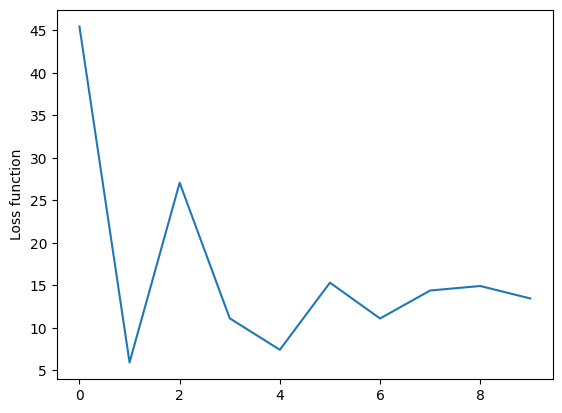

In [17]:
mini_optimizer = MinibatchGradientDescent(
    num_dims=num_dims,
    learning_rate=0.008
)
mini_optimizer.fit(
    X_train=X_train,
    y_train=y_train,
    num_epochs=500,
    batch_size=5,
    random_state=1
)
# mini_optimizer.summerizer.plot_w(step=20)
mini_optimizer.summerizer.plot_loss(step=50)

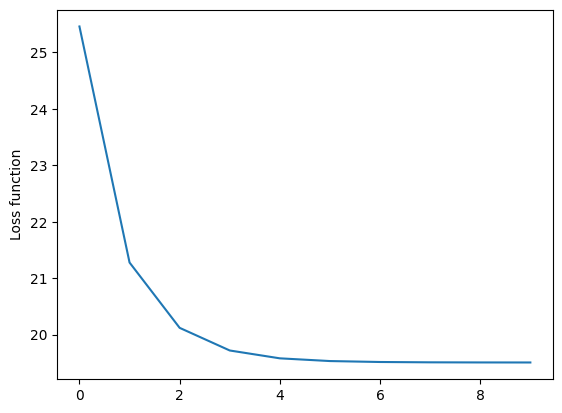

In [18]:
batch_optimizer = BatchGradientDescent(
    num_dims=num_dims,
    learning_rate=0.008
)
batch_optimizer.fit(
    X_train=X_train,
    y_train=y_train,
    num_epochs=500,
    random_state=1
)
# batch_optimizer.summerizer.plot_w(step=20)
batch_optimizer.summerizer.plot_loss(step=50)

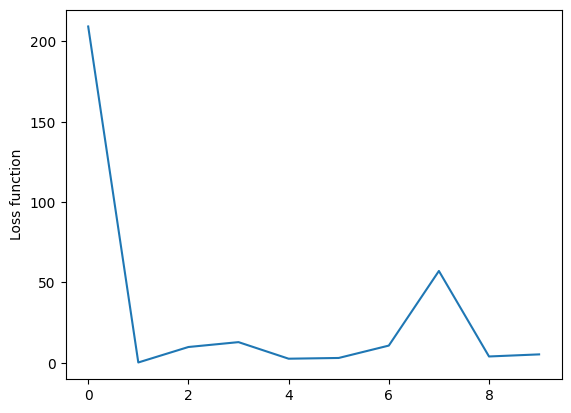

In [19]:
SGD_optimizer = StochasticGradientDescent(
    num_dims=num_dims,
    learning_rate=0.008
)
SGD_optimizer.fit(
    X_train=X_train,
    y_train=y_train,
    num_epochs=500,
    random_state=1
)
# SGD_optimizer.summerizer.plot_w(step=20)
SGD_optimizer.summerizer.plot_loss(step=50)

# Tham khảo

[An overview of gradient descent optimization algorithms](https://arxiv.org/pdf/1609.04747.pdf)